In [1]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import joblib
import json
import itertools
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, Bidirectional,
    GlobalAveragePooling1D, Flatten, BatchNormalization, Layer
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import gensim.downloader as api
import fasttext.util
import emoji

In [2]:
# === 1. Load Dataset ===
df = pd.read_csv('dataset_undersampled.csv')
df['content'] = df['content'].astype(str)
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,label
0,25e58f28-ad54-4f3f-829c-665b232c9985,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,"terimakasih Muntun, disaat semua org g ingat a...",5,0,NaN,16/06/2025 10:07,NaN,NaN,NaN,positive
1,529e569a-9be0-49ef-98dc-da2a5a505996,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,game ini saya kasih bintang 5 karena game mobi...,5,0,NaN,27/06/2025 00:13,NaN,NaN,NaN,positive
2,190ea905-2e09-4a21-a4a5-e7314ae41b58,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Lumayan bagus aku suka semoga ada yg baru dari...,3,0,NaN,2024-10-16 12:44:21,NaN,NaN,NaN,positive
3,52411d42-20de-4852-8a06-2a7628107ca7,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Gem nya bagus gak kayak pubgi,5,0,NaN,2025-02-23 13:08:27,NaN,NaN,NaN,positive
4,02aab5d8-714a-4948-b58b-f86588f2052b,Pengguna Google,https://play-lh.googleusercontent.com/EGemoI2N...,Game yang bagus dapat banyak event menarik dan...,5,0,1.9.33.10117,2024-12-07 23:50:22,NaN,NaN,1.9.33.10117,positive


In [3]:
# === 2. Preprocessing ===
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def clean_text(text):
    text = text.lower()
    text = emoji.replace_emoji(text, replace='')  # Remove emoji
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s{2,}', ' ', text)
    return stemmer.stem(text.strip())

df['clean_text'] = df['content'].apply(clean_text)

# Save cleaned dataset
df.to_csv('dataset_cleaned.csv', index=False)

In [4]:
# === 3. Tokenization & Padding ===
MAX_NUM_WORDS = 10000
MAX_SEQUENCE_LENGTH = 100

tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

sequences = tokenizer.texts_to_sequences(df['clean_text'])
X = pad_sequences(sequences, maxlen=MAX_SEQUENCE_LENGTH)

In [5]:
# === 4. Label Encoding ===
le = LabelEncoder()
y = le.fit_transform(df['label'])

In [6]:
# === 5. Split Data ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [8]:
# === 6. Load Embeddings ===
print("Loading Word2Vec...")
word2vec_model = api.load("word2vec-google-news-300")
EMBEDDING_DIM = 300
word_index = tokenizer.word_index
embedding_matrix = np.zeros((min(MAX_NUM_WORDS, len(word_index) + 1), EMBEDDING_DIM))

for word, i in word_index.items():
    if i >= MAX_NUM_WORDS:
        continue
    try:
        embedding_vector = word2vec_model[word]
        embedding_matrix[i] = embedding_vector
    except KeyError:
        embedding_matrix[i] = np.random.normal(0, np.sqrt(0.25), EMBEDDING_DIM)

# Head Word2Vec
print("Head of Word2Vec Embedding Matrix:")
print(pd.DataFrame(embedding_matrix).head())

print("Loading FastText...")
fasttext.util.download_model('id', if_exists='ignore')
ft = fasttext.load_model('cc.id.300.bin')
embedding_matrix_fasttext = np.zeros((min(MAX_NUM_WORDS, len(word_index) + 1), EMBEDDING_DIM))

for word, i in word_index.items():
    if i >= MAX_NUM_WORDS:
        continue
    try:
        embedding_vector = ft.get_word_vector(word)
        embedding_matrix_fasttext[i] = embedding_vector
    except KeyError:
        embedding_matrix_fasttext[i] = np.random.normal(0, np.sqrt(0.25), EMBEDDING_DIM)

# Head FastText
print("Head of FastText Embedding Matrix:")
print(pd.DataFrame(embedding_matrix_fasttext).head())

Loading Word2Vec...
Head of Word2Vec Embedding Matrix:
        0         1         2         3         4         5         6    \
0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
1  0.429570  0.561908  0.320741  0.185483  0.661567  0.336672 -0.502187   
2  0.114746  0.052734  0.042969  0.004486  0.273438  0.071777  0.173828   
3 -0.057373  0.046631  0.214844  0.083008 -0.173828  0.015015  0.135742   
4 -0.164062 -0.068359  0.167969 -0.045898 -0.045654 -0.087402  0.018921   

        7         8         9    ...       290       291       292       293  \
0  0.000000  0.000000  0.000000  ...  0.000000  0.000000  0.000000  0.000000   
1 -0.951102  0.309220 -0.391060  ... -1.045681  0.221063 -0.346849  0.759365   
2 -0.198242  0.020752  0.118652  ... -0.212891  0.043213 -0.139648 -0.011597   
3 -0.056152 -0.241211  0.049072  ...  0.164062  0.281250 -0.112793  0.067383   
4  0.032959 -0.021729  0.175781  ... -0.159180 -0.013123  0.077637 -0.083984   

        294  

Head of FastText Embedding Matrix:
        0         1         2         3         4         5         6    \
0  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000   
1 -0.001197  0.002951 -0.001959  0.001287 -0.001370 -0.002670  0.003284   
2  0.093619 -0.032306 -0.124408  0.111717  0.065760 -0.002625  0.021502   
3  0.122294 -0.084063 -0.062133  0.197877 -0.129644 -0.095872  0.026275   
4  0.083445  0.006291 -0.038409  0.004026  0.153117 -0.046940  0.018835   

        7         8         9    ...       290       291       292       293  \
0  0.000000  0.000000  0.000000  ...  0.000000  0.000000  0.000000  0.000000   
1 -0.000782  0.001842 -0.000638  ...  0.000517 -0.000428  0.000471 -0.001555   
2 -0.003199  0.021145 -0.058373  ...  0.008041 -0.111542 -0.110883 -0.048553   
3  0.016142 -0.003915 -0.164884  ... -0.019713 -0.068277 -0.087009  0.057944   
4 -0.065971  0.073028 -0.071565  ... -0.048466 -0.008862 -0.025935 -0.047826   

        294       295       296  

In [16]:
# === Custom Attention Layer ===
class SimpleAttention(Layer):
    def __init__(self):
        super(SimpleAttention, self).__init__()

    def build(self, input_shape):
        self.W = self.add_weight(name="att_weight", shape=(input_shape[-1], 1),
                                 initializer="normal", trainable=True)
        self.b = self.add_weight(name="att_bias", shape=(input_shape[1], 1),
                                 initializer="zeros", trainable=True)
        super(SimpleAttention, self).build(input_shape)

    def call(self, x):
        e = tf.keras.backend.tanh(tf.keras.backend.dot(x, self.W) + self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        output = x * a
        return tf.keras.backend.sum(output, axis=1)

In [17]:
# === 7. Hyperparameters ===
EPOCHS = 20
BATCH_SIZE = 64
LSTM_UNITS = 64
DROPOUT_RATE = 0.4
LEARNING_RATE = 0.001
PATIENCE = 3

In [18]:
# === 8. Model Builder ===
def build_model(use_attention=False, use_dropout=False, bidirectional=False,
                embedding_type="none"):
    
    inputs = Input(shape=(MAX_SEQUENCE_LENGTH,))
    
    if embedding_type == "word2vec":
        embedding_layer = Embedding(
            input_dim=embedding_matrix.shape[0],
            output_dim=embedding_matrix.shape[1],
            weights=[embedding_matrix],
            input_length=MAX_SEQUENCE_LENGTH,
            trainable=False
        )(inputs)
    elif embedding_type == "fasttext":
        embedding_layer = Embedding(
            input_dim=embedding_matrix_fasttext.shape[0],
            output_dim=embedding_matrix_fasttext.shape[1],
            weights=[embedding_matrix_fasttext],
            input_length=MAX_SEQUENCE_LENGTH,
            trainable=False
        )(inputs)
    else:
        embedding_layer = Embedding(
            input_dim=MAX_NUM_WORDS,
            output_dim=128,
            input_length=MAX_SEQUENCE_LENGTH
        )(inputs)

    x = embedding_layer
    x = BatchNormalization()(x)

    lstm_kwargs = {
        "return_sequences": use_attention,
        "dropout": DROPOUT_RATE,
        "recurrent_dropout": DROPOUT_RATE,
        "kernel_regularizer": l2(0.001),
        "recurrent_regularizer": l2(0.001),
    }

    if bidirectional:
        x = Bidirectional(LSTM(LSTM_UNITS, **lstm_kwargs))(x)
    else:
        x = LSTM(LSTM_UNITS, **lstm_kwargs)(x)

    if use_attention:
        x = SimpleAttention()(x)

    if use_dropout:
        x = Dropout(DROPOUT_RATE)(x)

    outputs = Dense(1, activation='sigmoid', kernel_regularizer=l2(0.001))(x)
    model = Model(inputs, outputs)
    model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
    return model


In [ ]:
# === 9. Train-Evaluate Function ===
def train_and_evaluate(use_attention=False, use_dropout=False, bidirectional=False,
                       embedding_type="none", scenario_num=0):
    
    model = build_model(use_attention, use_dropout, bidirectional, embedding_type)

    start_train = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.25,
        verbose=1
    )
    train_time = time.time() - start_train

    start_test = time.time()
    y_pred_prob = model.predict(X_test)
    y_pred = (y_pred_prob > 0.5).astype("int32")
    test_time = time.time() - start_test

    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)

    os.makedirs('saved_models', exist_ok=True)
    model.save(f'saved_models/model_scenario_{scenario_num}.h5')

    os.makedirs('training_histories', exist_ok=True)
    pd.DataFrame(history.history).to_csv(f'training_histories/scenario_{scenario_num}_history.csv', index=False)

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - Scenario {scenario_num}')
    plt.savefig(f'training_histories/scenario_{scenario_num}_confusion_matrix.png')
    plt.close()

    return acc, history, train_time, test_time, report, scenario_num


In [20]:
# === 10. Definisikan Semua Skenario ===
feature_options = list(itertools.product([False, True], repeat=3))
embedding_options = ['none', 'word2vec', 'fasttext']
skenario_list = []

for emb in embedding_options:
    for combo in feature_options:
        skenario_list.append({
            "attention": combo[0],
            "dropout": combo[1],
            "bidirectional": combo[2],
            "embedding": emb
        })

# === 11. Jalankan Semua Skenario ===
results = []
histories = []
reports = []

for i, s in enumerate(skenario_list, 1):
    print(f"▶ Skenario {i}: {s}")
    acc, history, train_time, test_time, report, sk_num = train_and_evaluate(
        use_attention=s["attention"],
        use_dropout=s["dropout"],
        bidirectional=s["bidirectional"],
        embedding_type=s["embedding"],
        scenario_num=i
    )
    results.append({
        "scenario": i,
        "accuracy": acc,
        "train_time_sec": train_time,
        "test_time_sec": test_time,
        **s
    })
    histories.append((i, history))
    reports.append((i, report))

# === 12. Simpan Semua Hasil ===
results_df = pd.DataFrame(results)
results_df.to_csv("all_results.csv", index=False)

# === 13. Temukan Model Terbaik ===
best_result = results_df.sort_values(by="accuracy", ascending=False).iloc[0]
best_idx = best_result["scenario"]
best_report = dict(reports[best_idx - 1][1])

with open(f"best_model_classification_report_scenario_{best_idx}.json", "w") as f:
    json.dump(best_report, f, indent=4)

print("\n✅ Model terbaik:")
print(f"Skenario {best_idx} dengan akurasi {best_result['accuracy']:.4f}")

▶ Skenario 1: {'attention': False, 'dropout': False, 'bidirectional': False, 'embedding': 'none'}
Epoch 1/20
97/97 [==============================] - 38s 357ms/step - loss: 0.4933 - accuracy: 0.8688 - val_loss: 0.6936 - val_accuracy: 0.6990
Epoch 2/20
97/97 [==============================] - 34s 354ms/step - loss: 0.2380 - accuracy: 0.9616 - val_loss: 0.4525 - val_accuracy: 0.9585
Epoch 3/20
97/97 [==============================] - 34s 354ms/step - loss: 0.1583 - accuracy: 0.9808 - val_loss: 0.2783 - val_accuracy: 0.9546
Epoch 4/20
97/97 [==============================] - 34s 352ms/step - loss: 0.1163 - accuracy: 0.9868 - val_loss: 0.2023 - val_accuracy: 0.9595
Epoch 5/20
97/97 [==============================] - 35s 361ms/step - loss: 0.0934 - accuracy: 0.9901 - val_loss: 0.2121 - val_accuracy: 0.9483
Epoch 6/20
97/97 [==============================] - 35s 361ms/step - loss: 0.0789 - accuracy: 0.9911 - val_loss: 0.1908 - val_accuracy: 0.9585
Epoch 7/20
97/97 [==========================

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan folder history ada
history_dir = "training_histories"
os.makedirs("plots", exist_ok=True)

# Asumsikan 24 skenario
for scenario_num in range(1, 25):
    file_path = f"{history_dir}/scenario_{scenario_num}_history.csv"

    if not os.path.exists(file_path):
        print(f"⛔ File tidak ditemukan untuk Skenario {scenario_num}")
        continue

    # Load history
    history_df = pd.read_csv(file_path)

    # Plot
    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(history_df['loss'], label='Training Loss')
    plt.plot(history_df['val_loss'], label='Validation Loss')
    plt.title(f'Skenario {scenario_num} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Plot Accuracy
    if 'accuracy' in history_df.columns and 'val_accuracy' in history_df.columns:
        plt.subplot(1, 2, 2)
        plt.plot(history_df['accuracy'], label='Training Accuracy')
        plt.plot(history_df['val_accuracy'], label='Validation Accuracy')
        plt.title(f'Skenario {scenario_num} - Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

    plt.suptitle(f'Skenario {scenario_num}', fontsize=14)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(f"plots/scenario_{scenario_num}_plot.png")
    plt.close()
    print(f"✅ Plot disimpan untuk Skenario {scenario_num}")


✅ Plot disimpan untuk Skenario 1
✅ Plot disimpan untuk Skenario 2
✅ Plot disimpan untuk Skenario 3
✅ Plot disimpan untuk Skenario 4
✅ Plot disimpan untuk Skenario 5
✅ Plot disimpan untuk Skenario 6
✅ Plot disimpan untuk Skenario 7
✅ Plot disimpan untuk Skenario 8
✅ Plot disimpan untuk Skenario 9
✅ Plot disimpan untuk Skenario 10
✅ Plot disimpan untuk Skenario 11
✅ Plot disimpan untuk Skenario 12
✅ Plot disimpan untuk Skenario 13
✅ Plot disimpan untuk Skenario 14
✅ Plot disimpan untuk Skenario 15
✅ Plot disimpan untuk Skenario 16
✅ Plot disimpan untuk Skenario 17
✅ Plot disimpan untuk Skenario 18
✅ Plot disimpan untuk Skenario 19
✅ Plot disimpan untuk Skenario 20
✅ Plot disimpan untuk Skenario 21
✅ Plot disimpan untuk Skenario 22
✅ Plot disimpan untuk Skenario 23
✅ Plot disimpan untuk Skenario 24


In [25]:
# Ekstrak metrik dari classification report
metrics = []

for scenario_id, report in reports:
    macro = report.get('macro avg', {})
    micro = report.get('micro avg', {})
    weighted = report.get('weighted avg', {})

    metrics.append({
        "scenario": scenario_id,
        "macro_precision": macro.get("precision", 0),
        "macro_recall": macro.get("recall", 0),
        "macro_f1score": macro.get("f1-score", 0),
        "micro_precision": micro.get("precision", 0),
        "micro_recall": micro.get("recall", 0),
        "micro_f1score": micro.get("f1-score", 0),
        "weighted_precision": weighted.get("precision", 0),
        "weighted_recall": weighted.get("recall", 0),
        "weighted_f1score": weighted.get("f1-score", 0),
    })

# Buat DataFrame
metrics_df = pd.DataFrame(metrics)

# Gabungkan dengan results_df
full_results = pd.merge(results_df, metrics_df, on="scenario")

# Simpan ke file CSV baru
full_results.to_csv("all_metrics.csv", index=False)

print("✅ Metrik precision, recall, dan f1-score berhasil disimpan ke all_metrics.csv")


✅ Metrik precision, recall, dan f1-score berhasil disimpan ke all_metrics.csv


In [27]:
# === 12b. Simpan Precision, Recall, F1-Score per Label ===
detailed_metrics = []

for scenario_id, report in reports:
    for label_name in le.classes_:
        if label_name in report:
            row = {
                "scenario": scenario_id,
                "label": label_name,
                "precision": report[label_name]["precision"],
                "recall": report[label_name]["recall"],
                "f1_score": report[label_name]["f1-score"],
                "support": report[label_name]["support"]
            }
            detailed_metrics.append(row)

# Simpan ke file
detailed_df = pd.DataFrame(detailed_metrics)
detailed_df.to_csv("all_metrics_detailed.csv", index=False)
print("✅ Metrik per label disimpan ke 'all_metrics_detailed.csv'")


✅ Metrik per label disimpan ke 'all_metrics_detailed.csv'


Text(0.5, 1.0, 'Distribusi Panjang Ulasan Sebelum Padding')

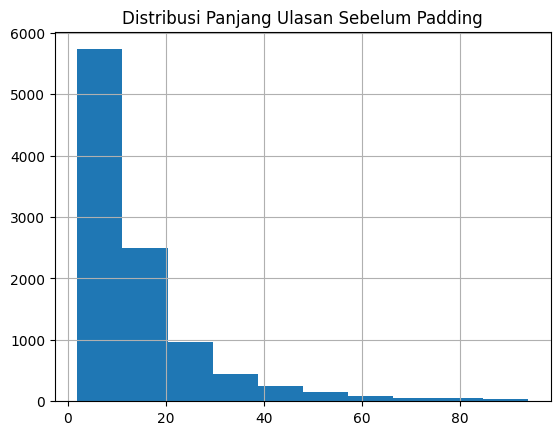

In [28]:
df['clean_text'].apply(lambda x: len(x.split())).hist()
plt.title("Distribusi Panjang Ulasan Sebelum Padding")


C:\Users\nurfa\AppData\Local\Temp\ipykernel_12040\912294490.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="scenario", y="accuracy", data=results_df, palette="viridis")


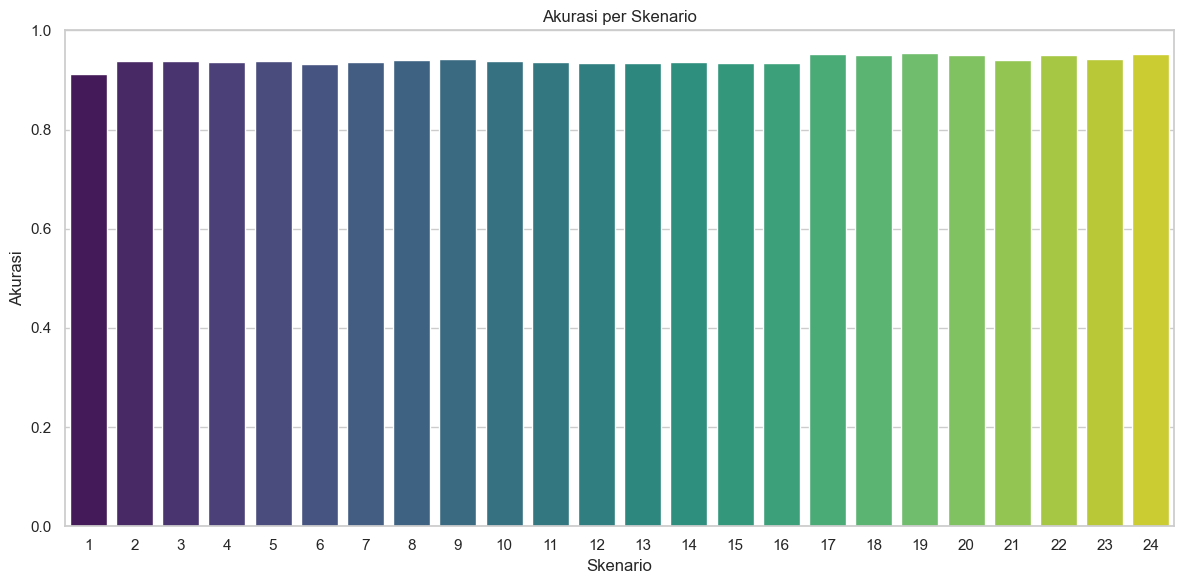

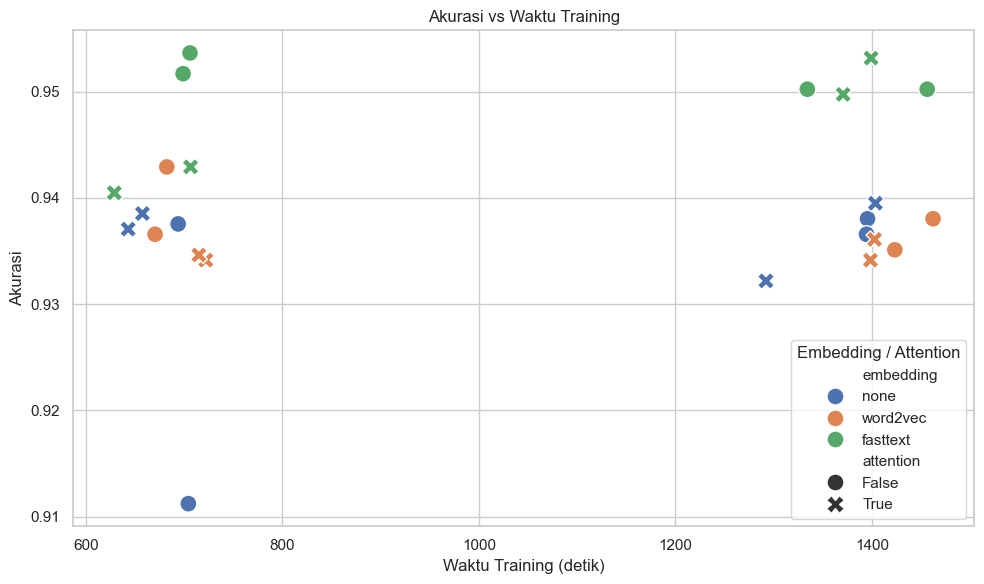

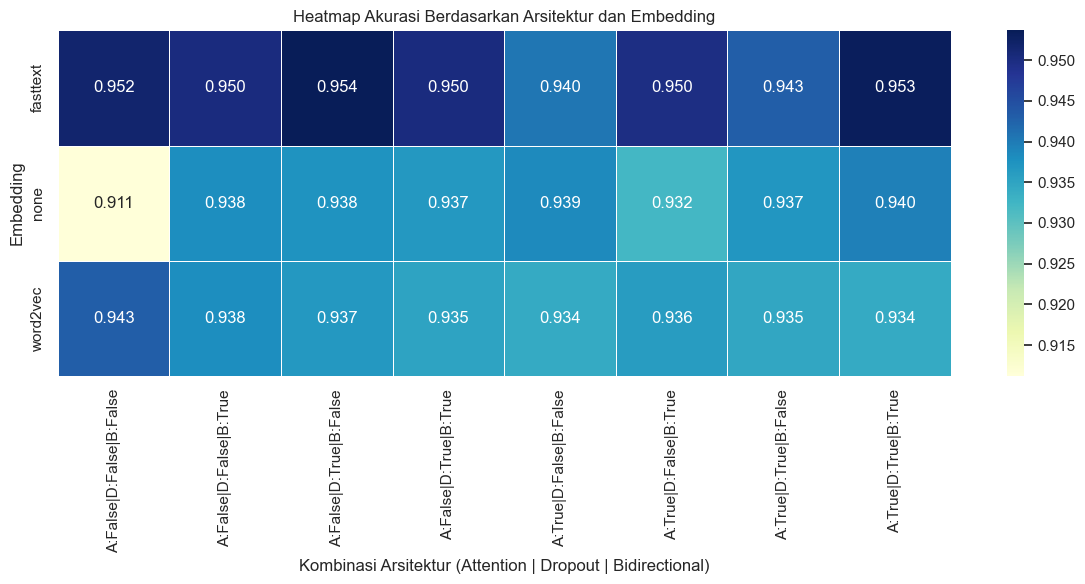

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gaya visual
sns.set(style="whitegrid")

# Load hasil semua skenario
results_df = pd.read_csv("all_results.csv")

# --- 1. Bar Chart Akurasi per Skenario ---
plt.figure(figsize=(12, 6))
sns.barplot(x="scenario", y="accuracy", data=results_df, palette="viridis")
plt.title("Akurasi per Skenario")
plt.xlabel("Skenario")
plt.ylabel("Akurasi")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# --- 2. Scatter Plot: Akurasi vs Waktu Training ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=results_df,
    x="train_time_sec",
    y="accuracy",
    hue="embedding",         # pakai 'embedding' sesuai data kamu
    style="attention",       # gunakan style berdasarkan attention
    s=150
)
plt.title("Akurasi vs Waktu Training")
plt.xlabel("Waktu Training (detik)")
plt.ylabel("Akurasi")
plt.legend(title="Embedding / Attention")
plt.tight_layout()
plt.show()


# --- 3. Heatmap: Attention, Dropout, Bidirectional vs Akurasi ---
# Gabungkan nilai boolean menjadi satu string untuk sumbu heatmap
results_df["arch"] = results_df.apply(
    lambda row: f"A:{row['attention']}|D:{row['dropout']}|B:{row['bidirectional']}", axis=1
)

# Buat pivot tabel: baris = embedding, kolom = kombinasi arsitektur, nilai = akurasi
pivot_table = results_df.pivot_table(
    index="embedding",   # sebelumnya salah: 'embedding_type'
    columns="arch",
    values="accuracy"
)

# Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, annot=True, cmap="YlGnBu", fmt=".3f", linewidths=0.5)
plt.title("Heatmap Akurasi Berdasarkan Arsitektur dan Embedding")
plt.xlabel("Kombinasi Arsitektur (Attention | Dropout | Bidirectional)")
plt.ylabel("Embedding")
plt.tight_layout()
plt.show()

In [34]:
print(results_df.head())
print(results_df.columns)

   scenario  accuracy  train_time_sec  test_time_sec  attention  dropout  \
0         1  0.911220      704.373470       2.217030      False    False   
1         2  0.938049     1395.486110       4.143793      False    False   
2         3  0.937561      693.976875       2.162686      False     True   
3         4  0.936585     1394.407986       4.164510      False     True   
4         5  0.938537      657.642752       2.275934       True    False   

   bidirectional embedding  precision  recall  f1_score  
0          False      none        NaN     NaN       NaN  
1           True      none        NaN     NaN       NaN  
2          False      none        NaN     NaN       NaN  
3           True      none        NaN     NaN       NaN  
4          False      none        NaN     NaN       NaN  
Index(['scenario', 'accuracy', 'train_time_sec', 'test_time_sec', 'attention',
       'dropout', 'bidirectional', 'embedding', 'precision', 'recall',
       'f1_score'],
      dtype='object')
